In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [4]:
noisy = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")

In [6]:
noisy.shape

(100, 6)

100 rows by 6 columns

In [8]:
print(noisy.head())
print(noisy.tail())

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


In [9]:
print(noisy.columns)

Index(['x', 'y_noise_1', 'y_noise_2', 'y_noise_3', 'y_noise_4', 'y_noise_5'], dtype='str')


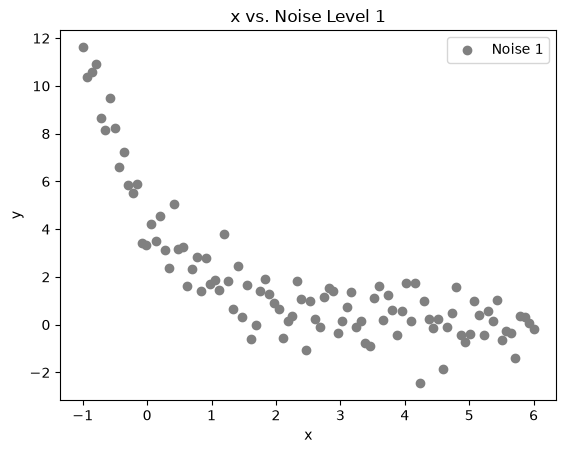

In [12]:
plt.scatter(noisy["x"], noisy["y_noise_1"], color = "gray", label="Noise 1")

plt.xlabel("x")
plt.ylabel("y")
plt.title("x vs. Noise Level 1")
plt.legend()

plt.show()

Fit: y = 4.71 * e^(-0.92 * x)


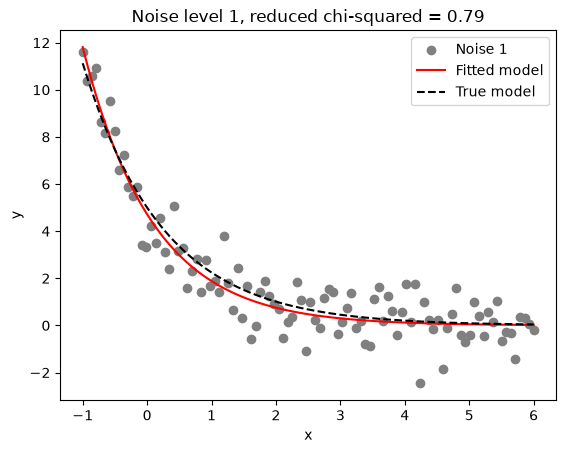

In [23]:
def model(x, A, k):
    return A * np.exp(-k * x)

p0 = [1, 1]
popt, pcov = curve_fit(model, noisy["x"], noisy["y_noise_1"], p0=p0)

A_fit, k_fit = popt
print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = noisy["y_noise_1"] - model(noisy["x"], A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(noisy["x"]) - len(popt)
chi2_reduced = chi2 / dof

plt.scatter(noisy["x"], noisy["y_noise_1"], color = "gray", label="Noise 1")

plt.plot(noisy["x"], model(noisy["x"], A_fit, k_fit), color="red", label="Fitted model")

plt.plot(noisy["x"], model(noisy["x"], 5, 0.8),
         color="black", linestyle="--", label="True model")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise level 1, reduced chi-squared = {chi2_reduced:.2f}")
plt.legend()

plt.show()

2.3 Compare Different Noise Levels